In [ ]:
# %% [markdown]
# # PBL Modelagem - validação do modelo com o MIMIC-IV (completo)
# Cada bloco "# %%" é uma célula (Jupyter / VS Code).
# Ordem: 1-6 preparam os dados | 7 basal vs modelo | 8 médias | 9 paciente por ID | 10 dose-resposta
# Tempo de referência (como no dashboard): minutos desde o INÍCIO da noradrenalina.

# %% 1. Configuração
import os, gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10, "legend.frameon": False})

try:                       # duckdb é opcional: sem ele, usa pandas (pyarrow p/ Parquet, ou CSV em blocos)
    import duckdb
except ImportError:
    duckdb = None
    print("duckdb não instalado: usando pandas (mais lento, mas funciona)")

# Pasta do MIMIC-IV (raiz com hosp/ e icu/, ou tudo junto). Defina a variável de ambiente MIMIC_DIR
# ou troque o valor padrão. O padrão é o mini-MIMIC sintético do projeto.
PASTA = os.environ.get("MIMIC_DIR", "mimic completo")
# Parquet gerado UMA vez por `python preparar_mimic.py PASTA` (segundos em vez de dezenas de minutos).
# Se não existir, o notebook lê os CSV, como antes.
PARQUET = os.environ.get("MIMIC_PARQUET", os.path.join(PASTA, "parquet"))
IDOSO = 65           # idade >= 65 = idoso

# Valores do modelo (Tabelas 2-3 do relatório / dashboard). Edite se mudar o modelo.
MODELO = {
    "adulto": {"pam": 58.0, "pas": 81, "pad": 38, "pp": 44},   # choque adulto
    "idoso":  {"pam": 62.1, "pas": 89, "pad": 39, "pp": 51},   # choque idoso (C × 0,79; era 103/29 com C × 0,5)
}
META_PAM = 65        # mmHg
COR = {"adulto": "tab:blue", "idoso": "tab:red"}

# Janela e passo das séries alinhadas (minutos desde a noradrenalina)
T0, T1, PASSO = -60, 240, 5
NMIN = 10            # mínimo de pacientes por ponto nas médias (menos que isso vira ruído)

# Limpeza (premissas: ajuste se o grupo definir outras)
DOSE_NE_PLAUSIVEL = 3.0   # µg/kg/min; estadia com nora acima disso tem erro de registro e sai inteira
MIN_ANTES_NE      = 60    # min; início "incidente" = nora começou >= 60 min depois da entrada na UTI
JANELA_NI         = 30    # min; PAM não invasiva só entra se não houver invasiva a menos disso
ID_PACIENTE       = None  # seção 9: subject_id ou stay_id; None = estadia com mais medidas de PAM


def _parquet(nome):
    cam = os.path.join(PARQUET, f"{nome}.parquet")
    return cam.replace(os.sep, "/") if os.path.exists(cam) else None

def _caminho(nome):
    for sub in ("", "hosp", "icu"):                      # o MIMIC-IV oficial separa hosp/ e icu/
        for ext in (".csv", ".csv.gz"):                  # e vem como .csv.gz
            cam = os.path.join(PASTA, sub, nome + ext)
            if os.path.exists(cam):
                return cam
    raise FileNotFoundError(f"{nome}.csv(.gz) não está em {PASTA} (nem em hosp/ ou icu/)")

def ler(nome, usecols=None, parse_dates=None, **kw):
    pq = _parquet(nome)
    if pq:                                               # Parquet: tipos (datas inclusive) já vêm certos
        if duckdb is not None:
            cols = ", ".join(f'"{c}"' for c in usecols) if usecols else "*"
            return duckdb.sql(f"SELECT {cols} FROM read_parquet('{pq}')").df()
        try:
            return pd.read_parquet(pq, columns=usecols)
        except ImportError:                              # sem pyarrow/fastparquet: cai para o CSV
            pass
    kw.update({k: v for k, v in (("usecols", usecols), ("parse_dates", parse_dates)) if v is not None})
    caminho = _caminho(nome)
    abre = gzip.open if caminho.endswith(".gz") else open
    with abre(caminho, "rt", encoding="utf-8-sig") as f:   # CSV salvo pelo Excel pode usar ";"
        cab = f.readline()
    sep = ";" if cab.count(";") > cab.count(",") else ","
    return pd.read_csv(caminho, sep=sep, encoding="utf-8-sig", low_memory=False, **kw)

def ler_chartevents(itemids, estadias):
    """Lê só as linhas de pressão das estadias com noradrenalina, sem carregar o arquivo inteiro na memória."""
    itemids = [int(i) for i in itemids]
    estadias = [int(s) for s in estadias]
    lista = ",".join(str(i) for i in itemids)
    cols = ["stay_id", "charttime", "itemid", "valuenum"]
    pq = _parquet("chartevents")
    if pq and duckdb is not None:
        con = duckdb.connect()
        con.register("estadias", pd.DataFrame({"stay_id": estadias}))
        return con.execute(f"""
            SELECT c.stay_id, c.charttime, c.itemid, c.valuenum
            FROM read_parquet('{pq}') c JOIN estadias e ON c.stay_id = e.stay_id
            WHERE c.itemid IN ({lista}) AND c.valuenum BETWEEN 10 AND 300""").df()
    if pq:
        try:                                             # pyarrow filtra na leitura
            d = pd.read_parquet(pq, columns=cols, filters=[("itemid", "in", itemids)])
            return d[d.stay_id.isin(estadias) & d.valuenum.between(10, 300)].reset_index(drop=True)
        except ImportError:
            pass
    caminho = _caminho("chartevents")
    if duckdb is None:
        print("lendo chartevents em blocos com pandas (sem duckdb), pode demorar")
        partes = []
        for bloco in pd.read_csv(caminho, usecols=cols, parse_dates=["charttime"], chunksize=2_000_000):
            partes.append(bloco[bloco.itemid.isin(itemids) & bloco.stay_id.isin(estadias)
                                & bloco.valuenum.between(10, 300)])
        return pd.concat(partes, ignore_index=True)
    con = duckdb.connect()
    con.register("estadias", pd.DataFrame({"stay_id": estadias}))
    return con.execute(f"""
        SELECT c.stay_id, c.charttime, c.itemid, c.valuenum
        FROM read_csv_auto('{caminho}', header = true) c
        JOIN estadias e ON c.stay_id = e.stay_id
        WHERE c.itemid IN ({lista}) AND c.valuenum BETWEEN 10 AND 300""").df()

In [6]:
# %% 2. Adultos e idosos
pac = ler("patients")
adm = ler("admissions", usecols=["hadm_id", "hospital_expire_flag"])
icu = (ler("icustays", parse_dates=["intime", "outtime"])
       .merge(pac, on="subject_id").merge(adm, on="hadm_id", how="left"))
icu["idade"] = icu.anchor_age + icu.intime.dt.year - icu.anchor_year
icu = icu[icu.idade >= 18].copy()
icu["grupo"] = np.where(icu.idade >= IDOSO, "idoso", "adulto")
print(icu.groupby("grupo").agg(estadias=("stay_id", "nunique"), idade_media=("idade", "mean")))

        estadias  idade_media
grupo                        
adulto        76    51.578947
idoso         64    76.406250


In [7]:

# %% 3. Choque séptico (CID-10 R65.21 / CID-9 785.52)
dx = ler("diagnoses_icd")
dx["icd_code"] = dx.icd_code.astype(str).str.replace(".", "", regex=False)
icu["choque_septico"] = icu.hadm_id.isin(dx[dx.icd_code.isin(["R6521", "78552"])].hadm_id)
print(icu.groupby("grupo").choque_septico.sum())

# Para filtrar o choque VASODILATADOR (seção 12): sepse por CID (não só o código de choque séptico) e
# os outros tipos de choque, que o modelo não representa. Prefixos valem para CID-9 e CID-10.
def _tem_cid(prefixos):
    return icu.hadm_id.isin(dx.loc[dx.icd_code.str.startswith(tuple(prefixos)), "hadm_id"])
icu["sepse"] = _tem_cid(["A40", "A41", "R6520", "R6521", "038", "99591", "99592", "78552"])
icu["choque_cardiogenico"] = _tem_cid(["R570", "78551"])
icu["choque_hipovolemico"] = _tem_cid(["R571", "T794", "78559", "9584"])   # hipovolêmico e traumático
print(icu.groupby("grupo")[["sepse", "choque_cardiogenico", "choque_hipovolemico"]].sum())

grupo
adulto     2
idoso     13
Name: choque_septico, dtype: int64


In [8]:

# %% 4. Noradrenalina e outros vasopressores
itens = ler("d_items")
def achar(rotulo):                      # itemid pelo nome exato do d_items
    return itens.loc[itens.label.str.lower() == rotulo.lower(), "itemid"].tolist()

# itemids dos outros vasopressores (por trecho do nome; "Phenylephrine (50/250)" etc. também contam).
# Angiotensina II entra aqui porque, em uso, a PAM deixa de refletir só a noradrenalina.
_in = itens[itens.linksto == "inputevents"]
def achar_contem(padrao, excluir=None):
    m = _in.label.str.contains(padrao, case=False, na=False)
    if excluir:
        m &= ~_in.label.str.contains(excluir, case=False, na=False)
    return _in.loc[m, "itemid"].tolist()

outros_ids = {}
for nome, padrao, excl in [("Epinephrine", "epinephrine", "nor"), ("Vasopressin", "vasopressin", None),
                           ("Phenylephrine", "phenylephrine", None), ("Dopamine", "dopamine", None),
                           ("AngiotensinaII", "angiotensin ii", None)]:
    for i in achar_contem(padrao, excl):
        outros_ids[i] = nome
ids_ne = achar("Norepinephrine")

inp = ler("inputevents", usecols=["stay_id", "itemid", "starttime", "endtime", "rate", "rateuom",
                                  "patientweight", "statusdescription"], parse_dates=["starttime", "endtime"])
inp = inp[inp.itemid.isin(set(ids_ne) | set(outros_ids))]      # descarta o resto do inputevents já na leitura
if "statusdescription" in inp:
    inp = inp[inp.statusdescription != "Rewritten"]
inp["horas"] = (inp.endtime - inp.starttime).dt.total_seconds() / 3600
inp = inp[inp.horas > 0]

_ne_todas = inp[inp.itemid.isin(ids_ne)].copy()
# mcg/min -> mcg/kg/min pelo peso registrado no próprio inputevents
conv = (_ne_todas.rateuom == "mcg/min") & (_ne_todas.patientweight > 0)
_ne_todas.loc[conv, "rate"] = _ne_todas.loc[conv, "rate"] / _ne_todas.loc[conv, "patientweight"]
_ne_todas.loc[conv, "rateuom"] = "mcg/kg/min"
# Estadias com unidade desconhecida ou dose implausível saem inteiras: tirar só o intervalo ruim deixaria um
# buraco que o validar.jl leria como dose zero.
outra_unid = _ne_todas.rateuom != "mcg/kg/min"
absurda = ~outra_unid & (_ne_todas.rate > DOSE_NE_PLAUSIVEL)
ruins = set(_ne_todas.loc[outra_unid | absurda, "stay_id"])
print(f"Noradrenalina: {conv.sum()} registros convertidos de mcg/min; {outra_unid.sum()} em outra unidade e "
      f"{absurda.sum()} acima de {DOSE_NE_PLAUSIVEL} µg/kg/min -> {len(ruins)} estadias excluídas "
      f"(de {_ne_todas.stay_id.nunique()})")
ne = _ne_todas[~_ne_todas.stay_id.isin(ruins)].copy()
ne["mg"] = ne.rate * ne.patientweight * ne.horas * 60 / 1000     # estimativa por taxa x peso x tempo

ne_uti = ne.groupby("stay_id").agg(
    dose_max=("rate", "max"), horas=("horas", "sum"), mg=("mg", "sum"),
    inicio=("starttime", "min"), fim=("endtime", "max"))
ne_uti["dose_media"] = ne.groupby("stay_id").apply(lambda g: np.average(g.rate, weights=g.horas))
ne_uti["horas_acima_0_2"] = ne[ne.rate >= 0.2].groupby("stay_id").horas.sum()
ne_uti["horas_acima_0_2"] = ne_uti.horas_acima_0_2.fillna(0)
ne_uti["refratario_proxy"] = ne_uti.horas_acima_0_2 >= 6    # proxy operacional, não é diagnóstico

# outros vasopressores (confundem a resposta da PAM): ids definidos acima
outros = (inp[inp.itemid.isin(outros_ids)].assign(droga=lambda d: d.itemid.map(outros_ids))
          .groupby("stay_id").droga.agg(lambda s: ",".join(sorted(set(s)))).rename("outros_vaso"))

icu = icu.merge(ne_uti.reset_index(), on="stay_id", how="left").merge(
    outros.reset_index(), on="stay_id", how="left")
icu["usou_ne"] = icu.dose_max.notna()
# Início incidente: a nora começou na UTI, com tempo para medir a PAM antes. Quem já chega com nora
# (do PS ou do centro cirúrgico) não tem PAM "antes da noradrenalina".
icu["min_ate_ne"] = (icu.inicio - icu.intime).dt.total_seconds() / 60
icu["inicio_incidente"] = icu.min_ate_ne >= MIN_ANTES_NE
print(f"Estadias com nora iniciada >= {MIN_ANTES_NE} min após a entrada na UTI: "
      f"{icu.inicio_incidente.sum()} de {icu.usou_ne.sum()}")
icu["outros_vaso"] = icu.outros_vaso.fillna("")
print(icu[icu.usou_ne].groupby("grupo")[["dose_max", "dose_media", "horas", "mg"]].median().round(2))

        dose_max  dose_media  horas     mg
grupo                                     
adulto      0.17        0.09  40.75  17.31
idoso       0.20        0.09  25.51   6.91


In [ ]:

# %% 5. Pressões arteriais (invasiva; se a estadia não tem, usa a não invasiva)
# "ART BP ..." (225309/225310/225312) é outra linha arterial no MIMIC-IV; sem ela parte das invasivas some
# Atenção: use pa["pad"], nunca pa.pad — DataFrame.pad é um método do pandas e "rouba" o nome da coluna.
ids = {"pam": achar("Arterial Blood Pressure mean") + achar("ART BP Mean"),
       "pas": achar("Arterial Blood Pressure systolic") + achar("ART BP Systolic"),
       "pad": achar("Arterial Blood Pressure diastolic") + achar("ART BP Diastolic"),
       "pam_ni": achar("Non Invasive Blood Pressure mean"),
       "pas_ni": achar("Non Invasive Blood Pressure systolic"),
       "pad_ni": achar("Non Invasive Blood Pressure diastolic")}
mapa = {i: k for k, v in ids.items() for i in v}
ch = ler_chartevents(list(mapa), set(ne_uti.index))     # só pressões, só estadias com noradrenalina
ch = ch[ch.itemid.isin(mapa) & ch.valuenum.between(10, 300)].copy()
ch["var"] = ch.itemid.map(mapa)

pa = ch.pivot_table(index=["stay_id", "charttime"], columns="var", values="valuenum").reset_index()
pa.columns.name = None
for c in ["pam", "pas", "pad", "pam_ni", "pas_ni", "pad_ni"]:
    if c not in pa:
        pa[c] = np.nan
# Invasiva tem prioridade, mas por HORÁRIO: a não invasiva entra quando não há invasiva a menos de JANELA_NI
# min (antes de o cateter ser colocado, que costuma ser justamente a PAM basal, ou depois de ele sair).
inv = pa["pam"].notna()
t_inv = pa.loc[inv, ["stay_id", "charttime"]].rename(columns={"charttime": "t_inv"}).sort_values("t_inv")
cand = pa.loc[~inv, ["stay_id", "charttime"]].reset_index().sort_values("charttime")
prox = pd.merge_asof(cand, t_inv, left_on="charttime", right_on="t_inv", by="stay_id", direction="nearest")
longe = prox.t_inv.isna() | ((prox.charttime - prox.t_inv).abs() > pd.Timedelta(minutes=JANELA_NI))
usa_ni = np.zeros(len(pa), dtype=bool)
usa_ni[prox.loc[longe, "index"].to_numpy()] = True
for c in ["pam", "pas", "pad"]:
    pa[c] = np.where(usa_ni, pa[c + "_ni"], pa[c])
pa["fonte"] = np.where(usa_ni, "nao_invasiva", "invasiva")
pa = pa.dropna(subset=["pam"])
# Artefatos (flush, amortecimento da linha): com PAS e PAD presentes, exige PAD < PAM < PAS e PP >= 10
tres = pa[["pas", "pad"]].notna().all(axis=1)
consistente = ~tres | ((pa["pad"] < pa["pam"]) & (pa["pam"] < pa["pas"]) & (pa["pas"] - pa["pad"] >= 10))
print(f"Medidas descartadas por PAD < PAM < PAS ou PP >= 10 violados: {(~consistente).sum()} de {len(pa)}")
pa = pa[consistente].copy()
pa["pp"] = pa["pas"] - pa["pad"]
pa = pa.merge(icu[["stay_id", "grupo"]], on="stay_id")
print(pa.groupby(["grupo", "fonte"]).agg(medidas=("pam", "size"), estadias=("stay_id", "nunique"),
                                         pam=("pam", "mean")).round(1))


In [10]:

# %% 6. IECA e BRA (prescrições; é uso no hospital, não uso crônico domiciliar)
nomes = ("lisinopril|enalapril|captopril|ramipril|benazepril|fosinopril|quinapril|perindopril|"
         "losartan|valsartan|candesartan|telmisartan|olmesartan|irbesartan")
rx = ler("prescriptions", parse_dates=["starttime"])
rx = rx[rx.drug.str.contains(nomes, case=False, na=False)].copy()
rx["classe"] = np.where(rx.drug.str.contains("sartan", case=False), "BRA", "IECA")
rx = rx.merge(icu[["stay_id", "hadm_id", "intime"]], on="hadm_id")
rx["antes_uti"] = rx.starttime < rx.intime
raas = rx.groupby("stay_id").agg(raas=("classe", lambda s: "+".join(sorted(set(s)))),
                                 raas_antes_uti=("antes_uti", "any")).reset_index()
icu = icu.merge(raas, on="stay_id", how="left")
icu["raas"] = icu.raas.fillna("nenhum")
print(icu[icu.usou_ne].groupby(["grupo", "raas"]).stay_id.nunique())


grupo   raas    
adulto  BRA          1
        BRA+IECA     1
        IECA         3
        nenhum      10
idoso   BRA          1
        IECA         3
        nenhum      14
Name: stay_id, dtype: int64


In [11]:

# %% 7. Séries alinhadas ao início da noradrenalina (base para as médias)
grade = np.arange(T0, T1 + PASSO, PASSO)
_com_pa = set(pa.stay_id)                       # calcula uma vez só (antes era a cada estadia)
com_dados = [s for s in ne_uti.index if s in _com_pa]
_pa_por = dict(tuple(pa.groupby("stay_id")))     # PAM de cada estadia, separada uma vez
_ne_por = dict(tuple(ne.groupby("stay_id")))
print(f"Estadias com noradrenalina E pressão arterial: {len(com_dados)}")

def alinhar(sid):
    """PAM média por bin de 5 min e dose vigente, em minutos desde o início da noradrenalina."""
    ini, fim = ne_uti.at[sid, "inicio"], ne_uti.at[sid, "fim"]
    p = _pa_por[sid]
    tmin = (p.charttime - ini).dt.total_seconds().values / 60
    pam_g = p.pam.groupby(np.round(tmin / PASSO) * PASSO).mean().reindex(grade)
    s = _ne_por[sid]
    a = ((s.starttime - ini).dt.total_seconds() / 60).values
    b = ((s.endtime - ini).dt.total_seconds() / 60).values
    r = s.rate.values
    fim_min = (fim - ini).total_seconds() / 60
    dose = []
    for g in grade:
        m = (a <= g) & (g < b)
        dose.append(r[m].max() if m.any() else (0.0 if g < fim_min else np.nan))  # após o fim: sem dado
    return pam_g.values, np.array(dose)

PAM_M, DOSE_M = {}, {}
for sid in com_dados:
    PAM_M[sid], DOSE_M[sid] = alinhar(sid)
pam_df = pd.DataFrame(PAM_M, index=grade).T
dose_df = pd.DataFrame(DOSE_M, index=grade).T
grupo_de = icu.set_index("stay_id").grupo

# Estado basal (60 min antes da noradrenalina) vs. valores do modelo
basal = (pa.merge(ne_uti[["inicio"]].reset_index(), on="stay_id")
           .assign(t=lambda d: (d.charttime - d.inicio).dt.total_seconds() / 60)
           .query("-60 <= t < 0"))
tab = basal.groupby("grupo")[["pas", "pad", "pam", "pp"]].median().round(1)
tab_mod = pd.DataFrame(MODELO).T[["pas", "pad", "pam", "pp"]]
print("\nBasal observado (mediana, 60 min antes da noradrenalina):\n", tab)
print("\nModelo (choque):\n", tab_mod)


Estadias com noradrenalina E pressão arterial: 33

Basal observado (mediana, 60 min antes da noradrenalina):
           pas   pad   pam    pp
grupo                          
adulto  103.0  59.0  69.0  47.0
idoso    90.0  52.0  65.0  41.0

Modelo (choque):
           pas   pad   pam    pp
adulto   81.0  38.0  58.0  44.0
idoso   103.0  29.0  62.1  74.0


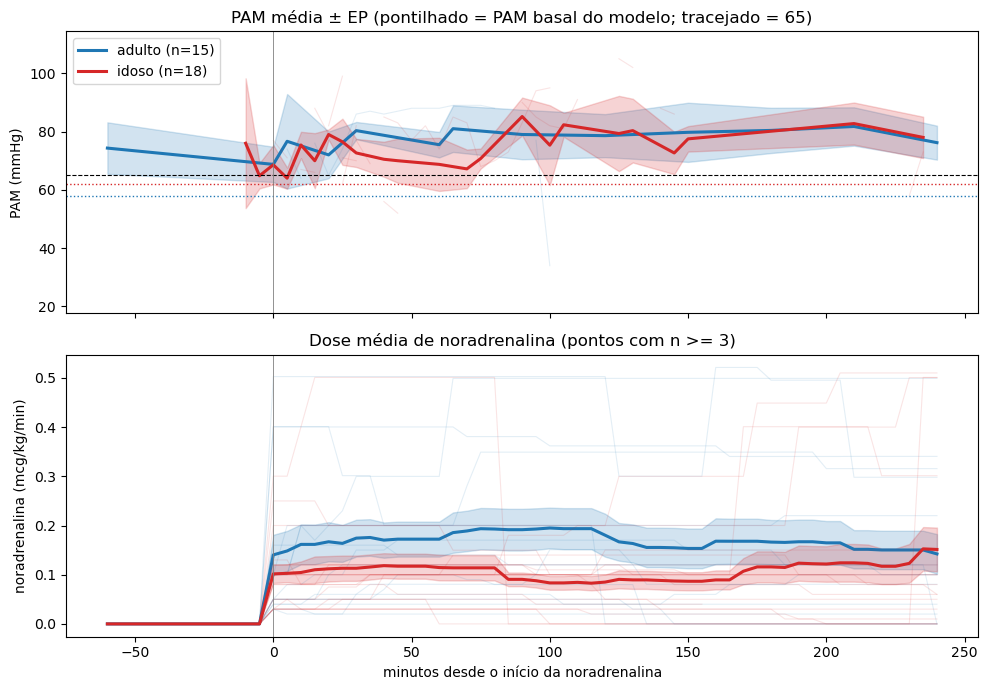

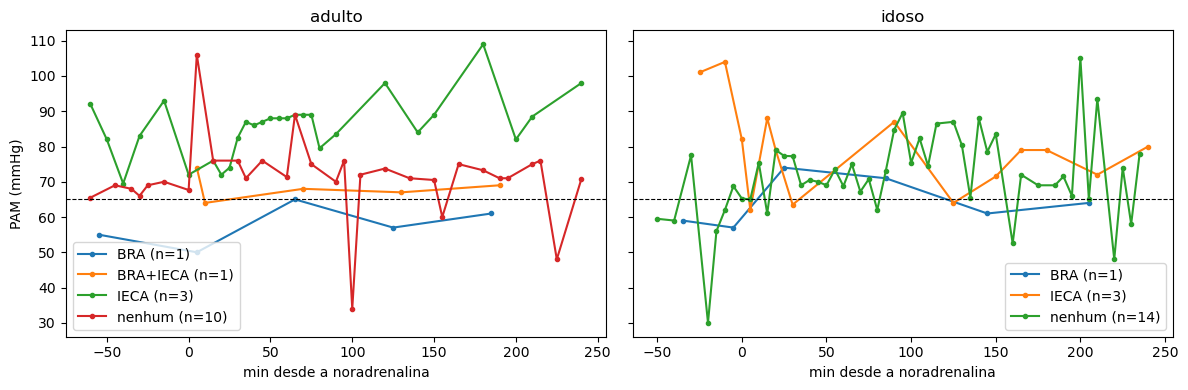

In [12]:

# %% 8. Gráficos MÉDIOS: PAM e dose de noradrenalina por grupo etário
MOSTRAR_INDIVIDUAIS = False     # True: linhas finas de pacientes sorteados ao fundo
MAX_INDIVIDUAIS = 200           # sorteia no máximo esse número por grupo

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for g in ["adulto", "idoso"]:
    ids_g = [s for s in com_dados if grupo_de[s] == g]
    if not ids_g:
        continue
    for axi, df, rotulo in [(ax[0], pam_df, "PAM"), (ax[1], dose_df, "dose")]:
        d = df.loc[ids_g]
        if MOSTRAR_INDIVIDUAIS:
            for _, linha in d.sample(min(len(d), MAX_INDIVIDUAIS), random_state=0).iterrows():
                axi.plot(grade, linha.values, color=COR[g], alpha=.12, lw=.8)
        m, n, e = d.mean(), d.count(), d.sem()
        ok = n >= NMIN
        axi.plot(grade[ok], m[ok], color=COR[g], lw=2.2, label=f"{g} (n={len(ids_g)})")
        axi.fill_between(grade[ok], (m - e)[ok], (m + e)[ok], color=COR[g], alpha=.2)
    ax[0].axhline(MODELO[g]["pam"], color=COR[g], ls=":", lw=1)   # PAM basal do modelo
ax[0].axhline(META_PAM, color="k", ls="--", lw=.8)
ax[0].set(ylabel="PAM (mmHg)", title="PAM média ± EP (pontilhado = PAM basal do modelo; tracejado = 65)")
ax[1].set(ylabel="noradrenalina (mcg/kg/min)", xlabel="minutos desde o início da noradrenalina",
          title=f"Dose média de noradrenalina (pontos com n >= {NMIN})")
ax[0].legend()
ax[0].axvline(0, color="gray", lw=.6); ax[1].axvline(0, color="gray", lw=.6)
plt.tight_layout(); plt.show()

# Mesma figura separando por exposição a IECA/BRA
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for axi, g in zip(ax, ["adulto", "idoso"]):
    for classe, d in icu[(icu.grupo == g) & icu.stay_id.isin(com_dados)].groupby("raas"):
        # bins de 15 min (média de cada estadia no bin, depois média entre estadias): com grupos pequenos,
        # bins de 5 min só mostram ruído. Só entram pontos com pelo menos NMIN estadias.
        p15 = pam_df.loc[d.stay_id].T.groupby((grade // 15) * 15).mean().T
        m, n, e = p15.mean(), p15.count(), p15.sem()
        ok = n >= NMIN
        if ok.sum() < 3:
            continue
        linha, = axi.plot(m.index[ok], m[ok], marker="o", ms=3, label=f"{classe} (n={len(d)})")
        axi.fill_between(m.index[ok], (m - e)[ok], (m + e)[ok], color=linha.get_color(), alpha=.15, lw=0)
    axi.axhline(META_PAM, color="k", ls="--", lw=.8)
    axi.axvline(0, color="gray", lw=.6)
    axi.set(title=f"{g}: PAM por uso de IECA/BRA (média ± EP, bins de 15 min)", xlabel="min desde a noradrenalina")
ax[0].set_ylabel("PAM (mmHg)"); ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


In [ ]:

# %% 9. Gráfico INDIVIDUAL: informe o ID do paciente (subject_id ou stay_id)
def plot_individual(sid):
    info = icu[icu.stay_id == sid].iloc[0]
    p = pa[pa.stay_id == sid].sort_values("charttime")
    s = ne[ne.stay_id == sid].sort_values("starttime")
    t0 = s.starttime.min() if len(s) else p.charttime.min()
    x = lambda ts: (ts - t0).dt.total_seconds() / 60

    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.fill_between(x(p.charttime), p["pad"], p["pas"], color="tab:red", alpha=.12, label="faixa PAD-PAS")
    ax.plot(x(p.charttime), p["pam"], "-o", ms=3, color="tab:red", label=f"PAM ({p.fonte.iloc[0]})")
    ax.axhline(META_PAM, color="k", ls="--", lw=.8, label="meta 65")
    ax.axhline(MODELO[info.grupo]["pam"], color="gray", ls=":", label=f"PAM basal do modelo ({info.grupo})")
    ax.set(xlabel="minutos desde o início da noradrenalina", ylabel="PAM (mmHg)")

    ax2 = ax.twinx()
    if len(s):
        ax2.hlines(s.rate, x(s.starttime), x(s.endtime), color="tab:blue", lw=3, label="noradrenalina")
        ax2.set_ylim(0, max(0.6, s.rate.max() * 1.15))
        ax.set_xlim(min(-120, x(p.charttime).min()), max(x(s.endtime).max() + 120, 60))
    ax2.set_ylabel("noradrenalina (mcg/kg/min)", color="tab:blue")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, fontsize=8)
    ax.set_title(f"subject {info.subject_id} | stay {sid} | {info.grupo}, {info.idade:.0f} anos | "
                 f"IECA/BRA: {info.raas} | outros vaso: {info.outros_vaso or 'nenhum'} | "
                 f"óbito hosp.: {'sim' if info.get('hospital_expire_flag') == 1 else 'não'}", fontsize=9)
    plt.tight_layout(); plt.show()

candidatos = icu[icu.usou_ne & icu.stay_id.isin(pa.stay_id)]
print("Candidatos (com noradrenalina e pressão arterial):")
print(f"{len(candidatos)} estadias; as 20 primeiras:")
print(candidatos[["subject_id", "stay_id", "grupo", "idade", "dose_max", "horas", "raas"]]
      .head(20).round(2).to_string(index=False))
# Escolha o paciente em ID_PACIENTE (seção 1) ou aqui; None = estadia com mais medidas de PAM.
if ID_PACIENTE is None:
    sugerido = pa[pa.stay_id.isin(candidatos.stay_id)].stay_id.value_counts().index[0]
    alvo = [sugerido]
else:
    n = int(ID_PACIENTE)
    alvo = icu[icu.stay_id == n].stay_id.tolist() or icu[icu.subject_id == n].stay_id.tolist()
if not alvo:
    print("ID não encontrado nas estadias de UTI.")
for sid in alvo:
    plot_individual(sid)


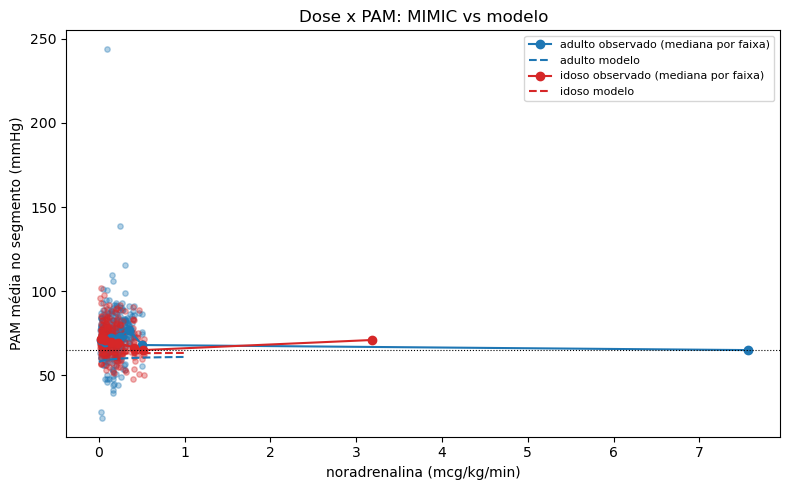

Atenção: a dose é titulada pela PAM (confusão por indicação); dose alta costuma coincidir com PAM baixa.


In [14]:

# %% 10. Dose-resposta observada vs. modelo (reconstrução do dashboard)
# Efeito da noradrenalina no modelo (aprox.): Rp = Rp_choque * (1 + E), E = Emax*C/(EC50 + C),
# com Emax = FRACAO * (65/PAM_basal - 1). PAM de equilíbrio ~ PAM_basal * (1 + E).
# Reconstruído a partir dos números do dashboard; confirme com o seu código do modelo.
FRACAO, EC50_NE = 0.5, 0.20

seg = (ne[ne.stay_id.isin(pa.stay_id)].merge(icu[["stay_id", "grupo"]], on="stay_id")
         .reset_index(drop=True))
seg["seg_id"] = np.arange(len(seg))
# Cada PAM vai para o último segmento de dose iniciado antes dela, se ele ainda estiver correndo.
# (Com duas linhas de nora sobrepostas, a PAM conta só para a mais recente.)
_p = pa[["stay_id", "charttime", "pam"]].assign(charttime=lambda d: d.charttime.astype("datetime64[ns]"))
_s = seg[["stay_id", "starttime", "endtime", "seg_id"]].assign(
    starttime=lambda d: d.starttime.astype("datetime64[ns]"), endtime=lambda d: d.endtime.astype("datetime64[ns]"))
_m = pd.merge_asof(_p.sort_values("charttime"), _s.sort_values("starttime"), left_on="charttime",
                   right_on="starttime", by="stay_id", direction="backward")
_m = _m[_m.charttime < _m.endtime]
seg["pam_seg"] = seg.seg_id.map(_m.groupby("seg_id").pam.mean())
seg = seg.dropna(subset=["pam_seg"])
FAIXAS_DOSE = [0, .05, .1, .15, .2, .3, .4, .5, .75, 1.0]
seg["faixa"] = pd.cut(seg.rate, FAIXAS_DOSE)

fig, ax = plt.subplots(figsize=(8, 5))
dose = np.linspace(0, 1.0, 100)
for g in ["adulto", "idoso"]:
    d = seg[seg.grupo == g]
    if len(d):
        b = d.groupby("faixa", observed=True).agg(x=("rate", "median"), q1=("pam_seg", lambda s: s.quantile(.25)),
                                                   y=("pam_seg", "median"), q3=("pam_seg", lambda s: s.quantile(.75)),
                                                   n=("stay_id", "nunique"))
        b = b[b.n >= NMIN]
        ax.fill_between(b.x, b.q1, b.q3, color=COR[g], alpha=.15, lw=0)
        ax.plot(b.x, b.y, "o-", color=COR[g], label=f"{g}: real (mediana e IIQ)")
    pam0 = MODELO[g]["pam"]
    emax = FRACAO * (META_PAM / pam0 - 1)
    ax.plot(dose, pam0 * (1 + emax * dose / (EC50_NE + dose)), "--", color=COR[g], label=f"{g}: modelo")
ax.axhline(META_PAM, color="k", ls=":", lw=.8)
ax.set(xlabel="noradrenalina (µg/kg/min)", ylabel="PAM média no segmento (mmHg)", xlim=(0, 1), ylim=(50, 90),
       title="Dose de noradrenalina × PAM: MIMIC vs modelo")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Atenção: a dose é titulada pela PAM (confusão por indicação); dose alta costuma coincidir com PAM baixa.")


In [15]:

# %% 11. Salvar resumo
cols = ["stay_id", "subject_id", "grupo", "idade", "choque_septico", "usou_ne", "dose_max",
        "dose_media", "horas", "mg", "refratario_proxy", "outros_vaso", "raas", "raas_antes_uti"]
icu[[c for c in cols if c in icu]].to_csv(f"{PASTA}/resumo_estadias.csv", index=False)
pam_df.to_csv(f"{PASTA}/pam_alinhada.csv"); dose_df.to_csv(f"{PASTA}/dose_alinhada.csv")

In [ ]:

# %% 12. Exportar para o validar.jl (pacientes.csv, serie_pam.csv, doses.csv)
# Tempo real de cada medida (sem a grade de 5 min), em minutos desde o início da noradrenalina.
# Coorte: "vasodilatador" = sepse, sem choque cardiogênico ou hipovolêmico, fora das UTIs cardiovascular e
# coronariana (lá a nora costuma ser pós-cirurgia cardíaca ou choque cardiogênico); "todos" = sem filtro.
# Cada coorte vai para uma pasta própria, para comparar os resultados.
COORTE = "vasodilatador"
UTIS_CARDIACAS = ["Cardiac Vascular Intensive Care Unit (CVICU)", "Coronary Care Unit (CCU)"]
EXPORT = f"{PASTA}/validacao" if COORTE == "todos" else f"{PASTA}/validacao_{COORTE}"
os.makedirs(EXPORT, exist_ok=True)
T_MAX_EXPORT   = 240      # min depois do início da noradrenalina
PAM_MIN_VALIDA = 30       # mmHg; abaixo disso é artefato
PAM_MAX_VALIDA = 180      # mmHg; acima disso é artefato (flush da linha arterial, erro de digitação)
EXCLUIR_OUTROS = True     # descarta a PAM medida enquanto outro vasopressor (ou angiotensina II) corre
SO_INICIO_INCIDENTE = True  # só estadias em que a nora começou na UTI (há PAM de verdade "antes")

estadias = set(ne_uti.index) & set(pa.stay_id)
if SO_INICIO_INCIDENTE:
    incid = set(icu.loc[icu.inicio_incidente.fillna(False).astype(bool), "stay_id"])
    print(f"Estadias em que a nora já corria ao entrar na UTI (saem): {len(estadias - incid)} de {len(estadias)}")
    estadias &= incid
if COORTE == "vasodilatador":
    _i = icu.set_index("stay_id")
    for nome, ok in [("com sepse (CID)", _i.sepse),
                     ("sem choque cardiogênico", ~_i.choque_cardiogenico),
                     ("sem choque hipovolêmico/traumático", ~_i.choque_hipovolemico),
                     ("fora das UTIs cardíacas", ~_i.first_careunit.isin(UTIS_CARDIACAS))]:
        antes = len(estadias)
        estadias = {s for s in estadias if bool(ok.get(s, False))}
        print(f"  {nome}: {antes} -> {len(estadias)} estadias")
estadias = sorted(estadias)
t_ini = ne_uti.inicio

ps = pa[pa.stay_id.isin(estadias) & pa.pam.between(PAM_MIN_VALIDA, PAM_MAX_VALIDA)].copy().reset_index(drop=True)
ps["t_min"] = (ps.charttime - ps.stay_id.map(t_ini)).dt.total_seconds() / 60
ps = ps[(ps.t_min >= -60) & (ps.t_min <= T_MAX_EXPORT)].reset_index(drop=True)

oth = inp[inp.itemid.isin(outros_ids) & inp.stay_id.isin(estadias)].copy()
oth["a"] = (oth.starttime - oth.stay_id.map(t_ini)).dt.total_seconds() / 60
oth["b"] = (oth.endtime - oth.stay_id.map(t_ini)).dt.total_seconds() / 60
if EXCLUIR_OUTROS and len(oth):
    m = ps[["stay_id", "t_min"]].reset_index(names="i").merge(oth[["stay_id", "a", "b"]], on="stay_id")
    cobertas = m.loc[(m.t_min >= m.a) & (m.t_min < m.b), "i"].unique()
    print(f"PAM descartada por outro vasopressor ativo: {len(cobertas)} de {len(ps)}")
    ps = ps.drop(index=cobertas)

base = (ps[ps.t_min <= 0].groupby("stay_id")
          .agg(pam0=("pam", "mean"), pas0=("pas", "mean"), pad0=("pad", "mean")))
pacientes = (icu[icu.stay_id.isin(estadias)][["stay_id", "subject_id", "intime", "grupo", "idade", "choque_septico", "refratario_proxy"]]
             .merge(base, left_on="stay_id", right_index=True, how="left")
             .rename(columns={"choque_septico": "septico", "refratario_proxy": "refratario"}))
pacientes[["septico", "refratario"]] = pacientes[["septico", "refratario"]].astype(int)
pacientes["intime"] = pacientes.intime.dt.strftime("%Y-%m-%d %H:%M:%S")   # o validar.jl ordena estadias por ela

dz = ne[ne.stay_id.isin(estadias)].copy()
dz["ini_min"] = (dz.starttime - dz.stay_id.map(t_ini)).dt.total_seconds() / 60
dz["fim_min"] = (dz.endtime - dz.stay_id.map(t_ini)).dt.total_seconds() / 60
dz = dz[(dz.fim_min > 0) & (dz.ini_min < T_MAX_EXPORT)][["stay_id", "ini_min", "fim_min", "rate"]].rename(columns={"rate": "taxa"})

pacientes.to_csv(f"{EXPORT}/pacientes.csv", index=False)
ps[["stay_id", "t_min", "pam", "pas", "pad"]].to_csv(f"{EXPORT}/serie_pam.csv", index=False)
dz.to_csv(f"{EXPORT}/doses.csv", index=False)
print(f"{len(pacientes)} estadias ({pacientes.subject_id.nunique()} sujeitos); "
      f"{pacientes.pam0.notna().sum()} com PAM antes da nora; {len(ps)} medidas de PAM; {len(dz)} intervalos de dose")
print(f"Gravado em {EXPORT}. Próximo passo:  julia validar.jl \"{EXPORT}\"")


In [ ]:

# %% 12b. Exportar FC, débito cardíaco (DC), volume sistólico e PVC: entradas da planta individual
# Mesmas estadias e mesma janela da seção 12. Lido por planta_individual.jl.
# Faixas plausíveis descartam erros de digitação. DC medido só existe em quem tinha monitor (cateter de
# Swan-Ganz, PiCCO, NICOM), então é uma minoria das estadias.
SINAIS = {"fc":  (["Heart Rate"], 20, 250),                                    # bpm
          "dc":  (["Cardiac Output (thermodilution)", "Cardiac Output (CCO)",
                   "Cardiac Output (CO NICOM)"], 1, 20),                       # L/min
          "vs":  (["Stroke Volume (SV NICOM)"], 10, 200),                      # ml
          "pvc": (["Central Venous Pressure"], -5, 40)}                        # mmHg
_ids = pd.DataFrame([(i, k, lo, hi) for k, (rot, lo, hi) in SINAIS.items() for r in rot for i in achar(r)],
                    columns=["itemid", "var", "lo", "hi"])
_pq = _parquet("chartevents")
if _pq is None or duckdb is None:
    raise RuntimeError("Esta seção precisa do Parquet (rode preparar_mimic.py) e do duckdb")
_con = duckdb.connect()
_con.register("est", pd.DataFrame({"stay_id": estadias}))
sv = _con.execute(f"""
    SELECT c.stay_id, c.charttime, c.itemid, c.valuenum
    FROM read_parquet('{_pq}') c JOIN est USING (stay_id)
    WHERE c.itemid IN ({",".join(map(str, _ids.itemid))}) AND c.valuenum IS NOT NULL""").df()
sv = sv.merge(_ids, on="itemid")
sv = sv[sv.valuenum.between(sv.lo, sv.hi)]
sv["t_min"] = (sv.charttime - sv.stay_id.map(t_ini)).dt.total_seconds() / 60
sv = sv[(sv.t_min >= -60) & (sv.t_min <= T_MAX_EXPORT)]
sinais = sv.pivot_table(index=["stay_id", "t_min"], columns="var", values="valuenum").reset_index()
for c in SINAIS:
    if c not in sinais:
        sinais[c] = np.nan
sinais[["stay_id", "t_min", *SINAIS]].to_csv(f"{EXPORT}/sinais.csv", index=False)
print("Estadias com cada sinal na janela:",
      {c: int(sinais.loc[sinais[c].notna(), "stay_id"].nunique()) for c in SINAIS})
print(f"Próximo passo:  julia planta_individual.jl \"{EXPORT}\"")


In [ ]:

# %% 13. Resultado do validar.jl: concordância (CCC de Lin) e Bland-Altman
# Como ler (detalhes no README.md da pasta):
#   * Gráfico de cima (prevista × medida): se o modelo acertasse, tudo cairia na diagonal tracejada.
#     A cor é a densidade de pontos; a linha vermelha é a mediana do modelo em cada faixa de PAM medida.
#     CCC de Lin = 1 é concordância perfeita; perto de 0, o modelo não acompanha a PAM real.
#   * Gráfico de baixo (Bland-Altman): erro (prevista − medida) contra o nível de PAM. A linha cheia é o
#     viés (erro médio) e as tracejadas, os limites de 95% (onde ficam 95% dos erros). A curva laranja mostra
#     se o erro muda com o nível de pressão; inclinada para baixo = o modelo não acompanha as PAM altas/baixas.
prev = pd.read_csv(f"{EXPORT}/previsao.csv")
met  = pd.read_csv(f"{EXPORT}/metricas.csv")
par  = pd.read_csv(f"{EXPORT}/parametros.csv")
print("Parâmetros ajustados em cada parte da validação cruzada:\n", par.round(3).to_string(index=False))

def ccc_lin(x, y):
    """Coeficiente de concordância de Lin: 2 cov / (var x + var y + (média x − média y)²)."""
    x, y = np.asarray(x), np.asarray(y)
    return 2 * np.cov(x, y, ddof=0)[0, 1] / (x.var() + y.var() + (x.mean() - y.mean()) ** 2)

# Tabela com TODOS os preditores: o modelo só acrescenta algo se ganhar das referências simples
linhas = []
for col, nome in [("pam_A", "modelo A (PAM do paciente)"), ("pam_B", "modelo B (PAM do grupo)"),
                  ("pam_const", "ref.: PAM fica igual"), ("pam_media", "ref.: média da população")]:
    e = prev[col] - prev.pam_obs
    linhas.append({"preditor": nome, "CCC de Lin": ccc_lin(prev.pam_obs, prev[col]), "viés": e.mean(),
                   "limite inferior": e.mean() - 1.96 * e.std(), "limite superior": e.mean() + 1.96 * e.std(),
                   "RMSE": np.sqrt((e ** 2).mean())})
print("\nConcordância com a PAM medida depois da nora (validação cruzada):")
print(pd.DataFrame(linhas).round(2).to_string(index=False))

LIM = (40, 140)                          # janela dos gráficos (mmHg)
faixas = np.arange(LIM[0], LIM[1] + 1, 5)
def mediana_por_faixa(v, ref):
    """Mediana de v em faixas de 5 mmHg de ref; só faixas com >= NMIN medidas (as outras são ruído)."""
    g = pd.Series(v).groupby(pd.cut(ref, faixas), observed=True).agg(["median", "size"])
    g = g[g["size"] >= NMIN]
    return [k.mid for k in g.index], g["median"].to_numpy()
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for j, (col, rot) in enumerate([("pam_A", "Modelo A: PAM inicial do paciente + nora"),
                                ("pam_B", "Modelo B: PAM do grupo (58/62) + nora")]):
    x, y = prev.pam_obs.to_numpy(), prev[col].to_numpy()

    a = ax[0, j]
    hb = a.hexbin(x, y, gridsize=40, extent=(*LIM, *LIM), bins="log", cmap="Blues", mincnt=1)
    a.plot(LIM, LIM, "k--", lw=1, label="acerto perfeito (prevista = medida)")
    a.plot(*mediana_por_faixa(y, x), color="tab:red", lw=2, label="mediana da prevista por faixa")
    fora = ((x < LIM[0]) | (x > LIM[1]) | (y < LIM[0]) | (y > LIM[1])).sum()
    a.set(xlim=LIM, ylim=LIM, xlabel="PAM medida (mmHg)", ylabel="PAM prevista pelo modelo (mmHg)",
          title=f"{rot}\nCCC de Lin = {ccc_lin(x, y):.2f}   ({fora} de {len(x)} pontos fora da janela)")
    a.legend(loc="upper left", fontsize=8)
    fig.colorbar(hb, ax=a, label="nº de medidas (escala log)")

    e, m = y - x, (y + x) / 2
    vies, sd = e.mean(), e.std()
    b = ax[1, j]
    hb2 = b.hexbin(m, e, gridsize=40, extent=(LIM[0], LIM[1], -60, 60), bins="log", cmap="Blues", mincnt=1)
    b.axhline(0, color="k", lw=.6)
    for yv, ls, txt in [(vies, "-", "viés"), (vies + 1.96 * sd, "--", "limite sup. 95%"),
                        (vies - 1.96 * sd, "--", "limite inf. 95%")]:
        b.axhline(yv, color="tab:red", ls=ls, lw=1.2)
        b.text(LIM[0] + 1, yv + 1, f"{txt}: {yv:+.1f}", color="tab:red", fontsize=8, va="bottom")
    b.plot(*mediana_por_faixa(e, m), color="tab:orange", lw=2, label="tendência do erro (mediana por faixa)")
    b.set(xlim=LIM, ylim=(-60, 60), xlabel="média entre prevista e medida (mmHg)",
          ylabel="erro: prevista − medida (mmHg)", title="Bland-Altman")
    b.legend(loc="lower left", fontsize=8)
    fig.colorbar(hb2, ax=b, label="nº de medidas (escala log)")
plt.tight_layout(); plt.show()

print(met[met.metrica.isin(["rmse", "habilidade"]) & (met.subgrupo == "todos")].round(3).to_string(index=False))


In [ ]:

# %% 14. Resposta a cada AUMENTO de dose: diferença em diferenças (desconta a regressão à média)
# Pergunta: quando a equipe aumenta a nora, a PAM sobe MAIS do que subiria sem o aumento?
#   Evento:   aumento de dose >= 20% e >= 0,02 µg/kg/min, com a nora já correndo.
#   Controle: instantes (a cada 15 min) da mesma coorte com nora correndo e dose ESTÁVEL
#             (nenhuma mudança >= 20% de 30 min antes até 45 min depois).
#   Nos dois: delta = PAM média de 15 a 45 min depois − PAM média nos 30 min antes.
#   Efeito da nora = delta(evento) − delta(controle com a MESMA PAM antes, em faixas de 5 mmHg, e a mesma
#   faixa de dose). PAM baixa tende a subir sozinha (regressão à média); o controle desconta essa parte.
#   IC 95%: bootstrap por paciente (as medidas de um paciente saem e entram juntas).
# Refratário em duas definições: "dose" (>= 6 h com nora >= 0,2, a antiga) e "2º vasopressor" (recebeu
# vasopressina, adrenalina, fenilefrina, dopamina ou Ang II na internação na UTI).
N_BOOT = 300
rng = np.random.default_rng(2026)
pam_v = pd.read_csv(f"{EXPORT}/serie_pam.csv")
dz_v  = pd.read_csv(f"{EXPORT}/doses.csv")
info  = pd.read_csv(f"{EXPORT}/pacientes.csv").set_index("stay_id")
info["refr_dose"]  = info.refratario.astype(bool)
info["refr_2vaso"] = icu.set_index("stay_id").outros_vaso.reindex(info.index).fillna("").ne("")

def _dose(g, t):
    m = (g.ini_min.to_numpy() <= t) & (t < g.fim_min.to_numpy())
    return g.taxa.to_numpy()[m].max() if m.any() else 0.0

def _janelas(p, t):
    a = p.pam[(p.t_min >= t - 30) & (p.t_min < t)]
    b = p.pam[(p.t_min >= t + 15) & (p.t_min <= t + 45)]
    return (a.mean(), b.mean()) if len(a) and len(b) else (np.nan, np.nan)

reg = []
_pam_por = dict(tuple(pam_v.groupby("stay_id")))
for sid, g in dz_v.groupby("stay_id"):
    p = _pam_por.get(sid)
    if p is None:
        continue
    mudancas = sorted(set(g.ini_min) | set(g.fim_min))
    for t in mudancas:                                        # eventos: aumentos de dose
        if t <= 0 or t > T_MAX_EXPORT - 45:
            continue
        de, para = _dose(g, t - 0.5), _dose(g, t + 0.5)
        if de > 0 and para >= 1.2 * de and para - de >= 0.02:
            reg.append((sid, "aumento", t, de, para, *_janelas(p, t)))
    for t in range(30, T_MAX_EXPORT - 45 + 1, 15):            # controles: dose estável
        d0 = _dose(g, t)
        if d0 <= 0:
            continue
        ds = [_dose(g, u) for u in range(t - 30, t + 46, 5)]
        if max(ds) < 1.2 * d0 and min(ds) > d0 / 1.2:
            reg.append((sid, "estável", t, d0, d0, *_janelas(p, t)))
did = pd.DataFrame(reg, columns=["stay_id", "tipo", "t", "dose_antes", "dose_depois", "pre", "pos"]).dropna()
did["delta"] = did.pos - did.pre
did = did.join(info[["subject_id", "grupo", "refr_dose", "refr_2vaso"]], on="stay_id")
did["pre_bin"] = (did.pre // 5) * 5
did["dose_faixa"] = np.where(did.dose_antes >= 0.2, ">= 0,2", "< 0,2")

# previsão do modelo para cada aumento (mesma regra da seção 10; equilíbrio, sem regressão à média)
def _efeito_modelo(r):
    pam0 = MODELO[r.grupo]["pam"]
    emax = FRACAO * (META_PAM / pam0 - 1)
    E = lambda d: emax * d / (EC50_NE + d)
    return r.pre * ((1 + E(r.dose_depois)) / (1 + E(r.dose_antes)) - 1)
did["delta_modelo"] = did.apply(_efeito_modelo, axis=1)

def _did(df):
    ev, ct = df[df.tipo == "aumento"], df[df.tipo == "estável"]
    mc = ct.groupby(["pre_bin", "dose_faixa"]).delta.mean().rename("delta_ctrl")
    ev = ev.join(mc, on=["pre_bin", "dose_faixa"]).dropna(subset=["delta_ctrl"])
    return (ev.delta - ev.delta_ctrl).mean(), ev.delta.mean(), ev.delta_ctrl.mean(), len(ev), ev.delta_modelo.mean()

def did_com_ic(df):
    est = _did(df)
    df = df.reset_index(drop=True)
    linhas_por_sub = list(df.groupby("subject_id").indices.values())   # posições de cada paciente
    boot = []
    for _ in range(N_BOOT):
        sorteio = rng.integers(0, len(linhas_por_sub), len(linhas_por_sub))
        boot.append(_did(df.iloc[np.concatenate([linhas_por_sub[k] for k in sorteio])])[0])
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return dict(efeito=est[0], ic_inf=lo, ic_sup=hi, delta_aumento=est[1], delta_controle=est[2],
                n_aumentos=est[3], modelo=est[4])

recortes = [("todos", did.tipo.notna()),
            ("dose < 0,2", did.dose_faixa == "< 0,2"), ("dose >= 0,2", did.dose_faixa == ">= 0,2"),
            ("adulto", did.grupo == "adulto"), ("idoso", did.grupo == "idoso"),
            ("refratário (dose)", did.refr_dose), ("não refratário (dose)", ~did.refr_dose),
            ("refratário (2º vasopressor)", did.refr_2vaso), ("não refratário (2º vasopressor)", ~did.refr_2vaso),
            ("2º vasopressor e dose >= 0,2", did.refr_2vaso & (did.dose_faixa == ">= 0,2"))]
res = pd.DataFrame([{"recorte": nome, **did_com_ic(did[m])} for nome, m in recortes])
res.to_csv(f"{EXPORT}/resposta_dose.csv", index=False)
print(f"{(did.tipo == 'aumento').sum()} aumentos de dose e {(did.tipo == 'estável').sum()} períodos de dose estável")
print(res.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
# esquerda: a regressão à média, que o controle desconta
for tipo, cor in [("estável", "gray"), ("aumento", "tab:blue")]:
    b = did[did.tipo == tipo].groupby("pre_bin").delta.agg(["mean", "sem", "size"])
    b = b[(b["size"] >= NMIN) & (b.index >= 40) & (b.index <= 100)]
    ax[0].errorbar(b.index + 2.5, b["mean"], yerr=1.96 * b["sem"], fmt="o-", color=cor, ms=4, capsize=2,
                   label=f"dose {'aumentada' if tipo == 'aumento' else 'estável'}")
ax[0].axhline(0, color="k", lw=.6); ax[0].axvline(META_PAM, color="k", ls=":", lw=.8)
ax[0].set(xlabel="PAM nos 30 min antes (mmHg)", ylabel="variação da PAM 15–45 min depois (mmHg)",
          title="Quanto mais baixa a PAM, mais ela sobe,\ncom ou sem aumento de dose (regressão à média)")
ax[0].legend()
# direita: efeito descontado, com IC, contra o previsto pelo modelo
y = np.arange(len(res))[::-1]
ax[1].errorbar(res.efeito, y, xerr=[res.efeito - res.ic_inf, res.ic_sup - res.efeito], fmt="o", color="tab:blue",
               capsize=3, label="dados: efeito do aumento (IC 95%)")
ax[1].scatter(res.modelo, y, marker="x", color="tab:red", s=50, zorder=3, label="modelo (previsão média)")
ax[1].axvline(0, color="k", lw=.6)
ax[1].set_yticks(y, [f"{r} (n={n})" for r, n in zip(res.recorte, res.n_aumentos)])
ax[1].set(xlabel="aumento da PAM atribuível ao aumento de dose (mmHg)",
          title="Diferença em diferenças: aumento de dose × dose estável\n(mesma PAM antes e mesma faixa de dose)")
ax[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()


In [ ]:

# %% 15. Angiotensina II no MIMIC: casos × controles pareados, com o desfecho do ATHOS-3
# ------------------------------------------------------------------------------------------------
# PERGUNTA: nos pacientes reais que receberam Ang II, a PAM respondeu como no ATHOS-3 e como o modelo prevê?
#
# DESENHO (definido antes de olhar os resultados):
#   * Casos: estadias com Ang II (d_items "Angiotensin II"). t = 0 no início da Ang II.
#   * Desfecho do ATHOS-3 na hora 3: PAM >= 75 OU subida >= 10 mmHg, SEM aumento dos outros vasopressores.
#     PAM basal = média de −60 a 0 min; PAM da hora 3 = média de 150 a 210 min (a PAM é esparsa).
#   * Controles ("placebo" do mundo real): estadias que NUNCA receberam Ang II, num instante em que a nora
#     estava >= 0,4 µg/kg/min. Cada caso é pareado com até K controles com PAM basal (±5 mmHg) e dose de
#     nora (±0,15) parecidas e o mesmo status de sepse. O efeito da Ang II é resposta(casos) − resposta(controles),
#     igual à comparação Ang II × placebo do ensaio.
#   * Modelo: para cada caso, a fórmula do modelo.jl (pam_com_aii, modo "nora fixa + Ang II") recebe a PAM basal
#     do paciente e as DOSES REAIS de Ang II (malha aberta; t½ 1 min). Emax 0,5 (central) e 0,3 a 1,0 (faixa);
#     r = 1 (sem BRA, porque o MIMIC não informa uso crônico); r = 11,9 como limite "todos com BRA".
#
# CUIDADOS E LIMITAÇÕES (também no README):
#   1. n muito pequeno (29 estadias no total; menos ainda com PAM nas duas janelas): resultado ILUSTRATIVO.
#   2. PAM esparsa: poucas medidas por janela; a média de uma janela pode ser 1 ou 2 medidas.
#   3. Não é ensaio randomizado: quem recebe Ang II é escolhido pela equipe (mais grave, resgate). O pareamento
#      por PAM, nora e sepse reduz, mas não elimina, a confusão. Fatores não medidos (lactato, volume, cortisol,
#      outros vasopressores em dose) podem diferir.
#   4. Regressão à média: Ang II começa quando a PAM está baixa; o controle pareado pela PAM basal desconta isso.
#   5. Sem dado de BRA/IECA crônico: o fator r, principal conclusão do modelo, NÃO é testável aqui.
#   6. Doses em duas unidades (ng/kg/min e µg/kg/min ×1000) e registros implausíveis (> 100 ng/kg/min) excluídos.
#   7. O modelo assume a nora FIXA; na vida real ela foi reduzida em parte dos casos (o modo "troca"), o que
#      o desfecho "sem aumentar vasopressores" tolera, mas a previsão do modelo não representa.
#   8. A Ang II do modelo foi calibrada com o próprio ATHOS-3 (Leisman 2024): comparar com o ATHOS-3 é
#      validação parcial; comparar com o MIMIC é externa, mas com n mínimo.
#   9. O modelo não tem "placebo": sem Ang II a PAM dele não muda (0% de resposta). Por isso a comparação
#      justa é o EFEITO (diferença entre braços), não a % de respondedores do braço Ang II.
#  10. O ATHOS-3 só incluiu PAM basal de 55 a 70 mmHg com nora-equivalente > 0,2; no MIMIC há casos com PAM
#      basal > 70 (que "respondem" quase por definição). Por isso há um recorte "como no ATHOS-3" (55 a 70).
#  11. Na prática a meta costuma ser 65, não 75: a equipe pode usar a Ang II para REDUZIR a nora em vez de subir
#      a PAM. Por isso também se compara a variação da dose de nora (desfecho secundário).
#  12. Pacientes de um centro; Ang II só existe nos anos mais recentes do MIMIC (aprovada no fim de 2017).
# ------------------------------------------------------------------------------------------------
JAN_BASE, JAN_H3 = (-60, 0), (150, 210)       # min desde o início da Ang II
NE_MIN_CTRL = 0.4                             # µg/kg/min: nora "alta" nos controles
TOL_PAM, TOL_NE, K_CTRL = 5.0, 0.15, 5        # pareamento
PAREAR_SEPSE = True
AII_MAX_PLAUS = 100.0                         # ng/kg/min; acima disso é erro de registro
ATHOS = {"Ang II": (114, 163), "placebo": (37, 158)}   # Khanna et al., NEJM 2017 (desfecho principal)
N_BOOT_AII = 2000
rng_aii = np.random.default_rng(2026)

def _min(ts):                                  # tempo absoluto em minutos (para comparar janelas)
    return (pd.to_datetime(ts) - pd.Timestamp("2000-01-01")).dt.total_seconds().to_numpy() / 60

# ---------------- doses de Ang II (ng/kg/min)
ids_aii = [i for i, n in outros_ids.items() if n == "AngiotensinaII"]
aii = inp[inp.itemid.isin(ids_aii)].copy()
aii["ng"] = np.select([aii.rateuom == "ng/kg/min", aii.rateuom == "mcg/kg/min"], [aii.rate, aii.rate * 1000], np.nan)
print(f"Ang II: {aii.stay_id.nunique()} estadias, {len(aii)} registros; unidades: {aii.rateuom.value_counts().to_dict()}")
ruim = aii.ng.isna() | (aii.ng > AII_MAX_PLAUS)
print(f"  registros excluídos (unidade desconhecida ou > {AII_MAX_PLAUS:.0f} ng/kg/min): {ruim.sum()}")
aii = aii[~ruim]
aii["a"], aii["b"] = _min(aii.starttime), _min(aii.endtime)
t0_aii = aii.groupby("stay_id").a.min()

# ---------------- séries por estadia em arrays (rápido)
_pa = pa[pa["pam"].between(30, 180)]
PAM_S = {s: (_min(g.charttime), g["pam"].to_numpy()) for s, g in _pa.groupby("stay_id")}
_ne = ne.assign(a=_min(ne.starttime), b=_min(ne.endtime))
NE_S = {s: (g.a.to_numpy(), g.b.to_numpy(), g.rate.to_numpy()) for s, g in _ne.groupby("stay_id")}
_oth = inp[inp.itemid.isin([i for i, n in outros_ids.items() if n != "AngiotensinaII"])]
_oth = _oth.assign(a=_min(_oth.starttime), b=_min(_oth.endtime), droga=_oth.itemid.map(outros_ids))
OUT_S = {s: g for s, g in _oth.groupby("stay_id")}

def taxa(series, t):
    a, b, r = series
    m = (a <= t) & (t < b)
    return r[m].max() if m.any() else 0.0

def janela(s, t0, jan):
    if s not in PAM_S:
        return np.nan, 0
    tt, v = PAM_S[s]
    m = (tt >= t0 + jan[0]) & (tt < t0 + jan[1]) if jan[1] <= 0 else (tt >= t0 + jan[0]) & (tt <= t0 + jan[1])
    return (v[m].mean() if m.any() else np.nan), int(m.sum())

def outros_aumentaram(s, t0):
    g = OUT_S.get(s)
    if g is None:
        return False
    for _, h in g.groupby("droga"):
        ser = (h.a.to_numpy(), h.b.to_numpy(), h.rate.to_numpy())
        if taxa(ser, t0 + 180) > taxa(ser, t0) * 1.1 + 1e-9:
            return True
    return False

def avaliar(s, t0):
    p0, n0 = janela(s, t0, JAN_BASE)
    p3, n3 = janela(s, t0, JAN_H3)
    ne0 = taxa(NE_S[s], t0) if s in NE_S else np.nan
    ne3 = taxa(NE_S[s], t0 + 180) if s in NE_S else np.nan
    sobe_vaso = (ne3 > ne0 * 1.05 + 0.01) or outros_aumentaram(s, t0)
    resp_pam = (p3 >= 75) or (p3 - p0 >= 10)
    return dict(stay_id=s, t0=t0, pam0=p0, n_base=n0, pam3=p3, n_h3=n3, delta=p3 - p0, ne0=ne0, ne3=ne3,
                aumentou_vaso=sobe_vaso, resposta_pam=resp_pam, resposta=resp_pam and not sobe_vaso)

info_icu = icu.set_index("stay_id")
casos = pd.DataFrame([avaliar(s, t) for s, t in t0_aii.items()])
casos = casos.join(info_icu[["subject_id", "grupo", "idade", "sepse", "first_careunit"]], on="stay_id")
ok_caso = casos.pam0.notna() & casos.pam3.notna() & casos.ne0.notna()
print(f"Casos: {len(casos)} estadias com Ang II; com PAM basal E na hora 3 E nora registrada: {ok_caso.sum()}")
print(f"  sem PAM basal: {casos.pam0.isna().sum()} | sem PAM na hora 3: {casos.pam3.isna().sum()} | "
      f"sem nora válida (fora da seção 4): {casos.ne0.isna().sum()}")
casos = casos[ok_caso].reset_index(drop=True)

# ---------------- controles: nunca receberam Ang II; 1 instante por estadia com nora >= 0,4
cand = []
for s, (a, b, r) in NE_S.items():
    if s in t0_aii.index or s not in PAM_S or r.max() < NE_MIN_CTRL:
        continue
    for t in np.arange(a.min(), b.max() - 180, 60):
        if taxa((a, b, r), t) >= NE_MIN_CTRL:
            d = avaliar(s, t)
            if not (np.isnan(d["pam0"]) or np.isnan(d["pam3"])):
                cand.append(d)
                break                                        # um instante por estadia (independência)
ctrl = pd.DataFrame(cand).join(info_icu[["grupo", "sepse"]], on="stay_id")
print(f"Controles possíveis (nora >= {NE_MIN_CTRL}, sem Ang II, PAM nas duas janelas): {len(ctrl)} estadias")

# ---------------- pareamento
pares = []
for i, c in casos.iterrows():
    m = ctrl[(ctrl.pam0.sub(c.pam0).abs() <= TOL_PAM) & (ctrl.ne0.sub(c.ne0).abs() <= TOL_NE)]
    if PAREAR_SEPSE:
        m = m[m.sepse == c.sepse]
    if len(m):
        dist = m.pam0.sub(c.pam0).abs() / TOL_PAM + m.ne0.sub(c.ne0).abs() / TOL_NE
        for j in dist.nsmallest(K_CTRL).index:
            pares.append((i, j))
pares = pd.DataFrame(pares, columns=["caso", "ctrl"])
casos["n_controles"] = casos.index.map(pares.groupby("caso").size()).fillna(0).astype(int)
com_par = casos[casos.n_controles > 0]
print(f"Casos com pelo menos 1 controle pareado: {len(com_par)} de {len(casos)} "
      f"(mediana de {com_par.n_controles.median():.0f} controles por caso)")

# ---------------- modelo (mesma fórmula do modelo.jl: pam_com_aii; EC50 calibrado por Emax como ec50_aii)
def ec50_aii(Emax):
    return 20.7 * (Emax * 66.0 / 9.1 - 1)

def pam_modelo_aii(s, t0, pam0, Emax=0.5, r=1.0):
    g = aii[aii.stay_id == s]
    ser = (g.a.to_numpy(), g.b.to_numpy(), g.ng.to_numpy())
    k = np.exp(-np.log(2) / 1.0)                             # t½ 1 min, passo de 1 min
    x, out = 0.0, {}
    for m in range(0, JAN_H3[1] + 1):
        u = taxa(ser, t0 + m)
        x = u + (x - u) * k
        out[m] = pam0 * (1 + Emax * x / (r * ec50_aii(Emax) + x))
    return np.mean([out[m] for m in range(JAN_H3[0], JAN_H3[1] + 1)]), out

for nome, Emax, r in [("modelo", 0.5, 1.0), ("modelo_E03", 0.3, 1.0), ("modelo_E10", 1.0, 1.0), ("modelo_BRA", 0.5, 11.9)]:
    casos[nome] = [pam_modelo_aii(c.stay_id, c.t0, c.pam0, Emax, r)[0] for c in casos.itertuples()]
    casos["resp_" + nome] = (casos[nome] >= 75) | (casos[nome] - casos.pam0 >= 10)
com_par = casos[casos.n_controles > 0]       # refeito com as colunas do modelo

# ---------------- comparação
def taxa_ic(k, n):
    p = k / n
    return p, 1.96 * np.sqrt(p * (1 - p) / n)

def efeito_pareado(df_casos):
    rc = df_casos.resposta.astype(float).to_numpy()
    rk = np.array([ctrl.loc[pares.ctrl[pares.caso == i], "resposta"].mean() for i in df_casos.index])
    dc = df_casos.delta.to_numpy()
    dk = np.array([ctrl.loc[pares.ctrl[pares.caso == i], "delta"].mean() for i in df_casos.index])
    nc = (df_casos.ne3 - df_casos.ne0).to_numpy()
    nk = np.array([(ctrl.ne3 - ctrl.ne0).loc[pares.ctrl[pares.caso == i]].mean() for i in df_casos.index])
    return rc.mean(), rk.mean(), (rc - rk).mean(), (dc - dk).mean(), dk.mean(), nc.mean(), nk.mean(), (nc - nk).mean()

def com_ic(df):
    boot = [efeito_pareado(df.loc[rng_aii.choice(df.index, len(df))]) for _ in range(N_BOOT_AII)]
    return efeito_pareado(df), np.nanpercentile(np.array(boot), [2.5, 97.5], axis=0)

est, ic = com_ic(com_par)
athos_like = com_par[com_par.pam0.between(55, 70)]
est2, ic2 = com_ic(athos_like)
pa_, ea_ = taxa_ic(*ATHOS["Ang II"]); pp_, ep_ = taxa_ic(*ATHOS["placebo"])
ef_athos = pa_ - pp_; ic_athos = 1.96 * np.sqrt(pa_ * (1 - pa_) / ATHOS["Ang II"][1] + pp_ * (1 - pp_) / ATHOS["placebo"][1])

tab_aii = pd.DataFrame([
    {"fonte": "ATHOS-3 (ensaio, n=163 × 158)", "resposta_AngII_%": 100 * pa_, "resposta_controle_%": 100 * pp_,
     "efeito_pp": 100 * ef_athos, "IC_inf": 100 * (ef_athos - ic_athos), "IC_sup": 100 * (ef_athos + ic_athos)},
    {"fonte": f"MIMIC pareado (n={len(com_par)} casos)", "resposta_AngII_%": 100 * est[0], "resposta_controle_%": 100 * est[1],
     "efeito_pp": 100 * est[2], "IC_inf": 100 * ic[0, 2], "IC_sup": 100 * ic[1, 2]},
    {"fonte": f"MIMIC pareado, PAM basal 55-70 como no ATHOS-3 (n={len(athos_like)})", "resposta_AngII_%": 100 * est2[0],
     "resposta_controle_%": 100 * est2[1], "efeito_pp": 100 * est2[2], "IC_inf": 100 * ic2[0, 2], "IC_sup": 100 * ic2[1, 2]},
    {"fonte": "Modelo, Emax 0,5 (doses reais dos casos)", "resposta_AngII_%": 100 * com_par.resp_modelo.mean(),
     "resposta_controle_%": 0.0, "efeito_pp": 100 * com_par.resp_modelo.mean(),
     "IC_inf": 100 * com_par[["resp_modelo_E03", "resp_modelo_E10"]].mean().min(),
     "IC_sup": 100 * com_par[["resp_modelo_E03", "resp_modelo_E10"]].mean().max()},
    {"fonte": "Modelo, todos com BRA (r = 11,9)", "resposta_AngII_%": 100 * com_par.resp_modelo_BRA.mean(),
     "resposta_controle_%": 0.0, "efeito_pp": 100 * com_par.resp_modelo_BRA.mean(), "IC_inf": np.nan, "IC_sup": np.nan}])
print("\nResposta na hora 3 (PAM >= 75 ou +10, sem aumentar vasopressores). Efeito = Ang II − controle, em pontos percentuais.")
print("Modelo: 'IC' = faixa de Emax 0,3 a 1,0 (não é intervalo de confiança); o modelo não tem placebo (0%).")
print(tab_aii.round(1).to_string(index=False))
print(f"\nVariação da PAM (hora 3 − basal), MIMIC: casos {com_par.delta.mean():+.1f}, controles "
      f"{est[4]:+.1f}; efeito {est[3]:+.1f} mmHg (IC {ic[0, 3]:+.1f} a {ic[1, 3]:+.1f}). "
      f"Modelo (Emax 0,5): {(com_par.modelo - com_par.pam0).mean():+.1f} mmHg.")
print(f"Dose de nora (hora 3 − início), MIMIC: casos {est[5]:+.3f}, controles {est[6]:+.3f} µg/kg/min; "
      f"efeito {est[7]:+.3f} (IC {ic[0, 7]:+.3f} a {ic[1, 7]:+.3f}). Modelo (modo nora fixa): 0 por construção.")
print(f"Recorte 55-70: variação da PAM, efeito {est2[3]:+.1f} mmHg (IC {ic2[0, 3]:+.1f} a {ic2[1, 3]:+.1f}); "
      f"modelo {(athos_like.modelo - athos_like.pam0).mean():+.1f} mmHg")
print(f"Resposta só pela PAM (ignorando vasopressores), casos: {100 * com_par.resposta_pam.mean():.0f}% | "
      f"casos em que a nora caiu em 3 h: {(com_par.ne3 < com_par.ne0 - 0.01).sum()} de {len(com_par)}")
os.makedirs(f"{PASTA}/angiotensina", exist_ok=True)
casos.to_csv(f"{PASTA}/angiotensina/casos.csv", index=False)
tab_aii.to_csv(f"{PASTA}/angiotensina/resumo.csv", index=False)

# ---------------- figuras
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
y = np.arange(len(tab_aii))[::-1]
ax[0].barh(y + .18, tab_aii["resposta_AngII_%"], .36, color="tab:orange", label="com Ang II")
ax[0].barh(y - .18, tab_aii["resposta_controle_%"], .36, color="gray", label="controle / placebo")
ax[0].set_yticks(y, tab_aii.fonte); ax[0].set(xlabel="% de respondedores na hora 3", xlim=(0, 100),
                                               title="Resposta pelo critério do ATHOS-3")
ax[0].legend(loc="lower right", fontsize=8)
ax[1].errorbar(tab_aii.efeito_pp, y, xerr=[(tab_aii.efeito_pp - tab_aii.IC_inf).fillna(0),
                                            (tab_aii.IC_sup - tab_aii.efeito_pp).fillna(0)],
               fmt="o", color="tab:orange", capsize=4)
ax[1].axvline(0, color="k", lw=.6)
ax[1].set_yticks(y, [""] * len(y)); ax[1].set(xlabel="efeito da Ang II (pontos percentuais)", xlim=(-60, 100),
                                               title="Efeito = Ang II − controle\n(modelo: barra = Emax 0,3 a 1,0)")
plt.tight_layout(); plt.show()

nc = 6; nl = int(np.ceil(len(casos) / nc))
fig, axs = plt.subplots(nl, nc, figsize=(3.1 * nc, 2.4 * nl), sharex=True, sharey=True, squeeze=False)
for a_, c in zip(axs.flat, casos.itertuples()):
    tt, v = PAM_S[c.stay_id]; m = (tt >= c.t0 - 60) & (tt <= c.t0 + 240)
    a_.plot(tt[m] - c.t0, v[m], "o", ms=3, color="k")
    _, traj = pam_modelo_aii(c.stay_id, c.t0, c.pam0)
    a_.plot(list(traj), list(traj.values()), color="tab:orange", lw=1.5)
    a_.axvspan(*JAN_H3, color="gray", alpha=.12)
    a_.axhline(75, color="tab:green", ls=":", lw=.8); a_.axhline(65, color="gray", ls=":", lw=.8)
    a_.set_title(f"{c.grupo}, {c.idade:.0f} a · nora {c.ne0:.2f}→{c.ne3:.2f}\n"
                 f"{'responde' if c.resposta else 'não responde'} (modelo: {'sim' if c.resp_modelo else 'não'})", fontsize=7)
for a_ in axs.flat[len(casos):]:
    a_.axis("off")
for a_ in axs[-1]:
    a_.set_xlabel("min desde a Ang II", fontsize=8)
axs[0, 0].set_ylim(40, 110)
fig.suptitle("Cada caso com Ang II: PAM medida (pontos) e PAM prevista pelo modelo com as doses reais (laranja). "
             "Faixa cinza = janela da hora 3; verde = 75; cinza = 65", fontsize=10)
plt.tight_layout(); plt.show()
